
# I. RPM Dataset

## 1. RPM Test:

An ***RPM*** or **R**.**A**.**V**.**E**.**N** (**R**elational and **A**nalogical r**E**aso**N**ing) **P**rogressive **M**atrices is a classical psychometrique test for human fluide intelligence, this is the first RPM dataset to afford tree-structures annotations making a semantic link between visual perception and structural reasoning.

An **RPM** is mainly a 3X3 mtarix having the last (index = [2,2]) position is missing : 

<table>
    <tr>
        <td>PANEL 1</td>
        <td>PANEL 2</td>
        <td>PANEL 3</td>
    </tr>
    <tr>
        <td>PANEL 4</td>
        <td>PANEL 5</td>
        <td>PANEL 6</td>
    </tr>
    <tr>
        <td>PANEL 7</td>
        <td>PANEL 8</td>
        <td>PANEL 9</td>
    </tr>
</table>

Answer candidates: [A] [B] [C] [D] [E] [F] [G] [H]  (8 candidats)

## 2. RPM Dataset

RAVEN dataset is generated using the project [DhiaEddineSaidi/RAVEN](https://github.com/DhiaEddineSaidi/RAVEN) forked from the original [WellyZhang/RAVEN](https://github.com/WellyZhang/RAVEN) repo for the purposes of fixing bugs and versions.

### Output Files
The dataset files :  
```
dataset/
├── center_single/
│   ├── RAVEN_0_train.npz    ← Problem 0, split train
│   ├── RAVEN_0_train.xml    ← Annotations XML
│   ├── RAVEN_1_train.npz
│   ...
│   ├── RAVEN_N_val.npz      ← Split validation
│   ├── RAVEN_N_test.npz     ← Split test
├── distribute_four/
├── distribute_nine/
├── left_center_single_right_center_single/
├── up_center_single_down_center_single/
├── in_center_single_out_center_single/
└── in_distribute_four_out_center_single/ 
```

### NPZ File
Each npz file contains the following:

* 'image': a (16, 160, 160) array where all 16 figures in each problem are stacked on the first dimension. Note that first 8 figures compose the problem matrix and the last 8 figures are choices.
* 'target': the index of the correct answer in the answer set. Note that it starts from 0 and you should offset it by 8 if you want to retrieve it from the image array.
* 'structure': the tree structure annotation for the problem. It's serialized into a sequence using pre-order traversal.
* 'meta_matrix': similar to that in PGM. Detailed ordering could be found in ```src/dataset/const.py```.
* 'meta_target': bitwise-or of meta_matrix on all rows. 
* 'meta_structure': it's similar to meta_matrix. Detailed ordering is in ```src/dataset/const.py```.
### XML File
Each xml file contains the following:

* Context panels and choice panels: each Panel could be further decomposed into Struct, Component, Layout, and Entity.
  * Each layer comes with its name and id if necessary.
  * Layout has its own attributes, whose values are indices into the value set (see also ```src/dataset/const.py```), except Position. Position is a list of slots entities could occupy, denoted by center and width/height. 
  * Entity's attributes follow the same annotation. The bbox is retrieved from the Position array in its parent Layout and the real_bbox is the actual bounding box, denoted by center and width/height. The mask is encoded using the run-length encoding. To decode it, use the ```rle_decode``` function in ```src/dataset/api.py```.
* Rules: rules are divided into groups, each of which applies to the corresponding component with the same id number. 
  * ```attr``` could be ```Number/Position``` when the rule is ```Constant``` as these two attributes are deeply coupled.
  * When there is a rule on ```Number``` or ```Position```, we omit the rule on the other attribute, as it should be assumed **as is**, *i.e.*, following the rule on the other (could remain unchanged).
  * Therefore, each rule group has 4 rules.

```xml
  <Data>
        <Panels>
            <Panel>
                <Struct name=''>
                    <Component id='' name=''>
                        <Layout name='' Number='' Position=''>
                            <Entity bbox='' real_bbox='' mask='' Type='' Size='' Color='' Angle=''/>
                            <!-- dependds on structure -->        
                            <Entity/>
                            ....
                            <Entity/>
                        </Layout>
                    </Component>
                    <!-- dependds on structure -->
                    <Component></Component>    
                </Struct>
            <Panel>
        </Panels>
        <Rules>
            <Rule_Group id=''>
                <Rule name='' attr=''/>
                <Rule name='' attr=''/>
                <Rule name='' attr=''/>
                <Rule name='' attr=''/>
            </Rule_Group>
            <!-- dependds on structure -->
            <Rule_Group></Rule_Group>
        </Rules>
    </Data>
```

## 3. RAVEN Structure
The structure of RAVEN is designed by associating each problem instance with a sentence derived from a stochastic image grammar [(A-SIG)](https://dash.harvard.edu/entities/publication/73120378-84d2-6bd4-e053-0100007fdf3b); specifically, the A-SIG serves as the representation for the RPM, and each RPM is a parse tree instantiated from the [(A-SIG)](https://dash.harvard.edu/entities/publication/73120378-84d2-6bd4-e053-0100007fdf3b). After [rules](#3-rpm-rules) are sampled, the grammer is prunned (trimmed down or reduced by ermoving extra unwanted parts).

Generated Panels consist of scenes. Each scene contains a structure composed of 1 or 2 components. Each component has 1 layout, and each layout contains 1 to 9 entities.

![raven structure](../../assets/images/raven_structure.png)

## 3.1. Attributes 
Each entity (geometrique Object) has 7 attributes, 5 rule-governing attributrs and 2 noise attributes, each rule-governing attribute goes over one of 4 [rules](#3-rpm-rules) : 

<table>
  <tr>
    <th>Attribute</th>
    <th>Attribute type</th>
    <th>Possible values (Real)</th>
    <th>Possible Values (Mapping)</th>
    <th>Constraint type</th>
    <th>Description</th>
  </tr>
  <tr>
    <td>1. Number</td>
    <td>Rule-governing</td>
    <td>[0,1,2,3,4,5,6,7,8]</td>
    <td>[1,2,3,4,5,6,7,8,9]</td>
    <td>Layout</td>
    <td>The number of `Entity(ies)` in that `Layout`</td>
  </tr>
  <tr>
    <td>2. Position</td>
    <td>Rule-governing</td>
    <td>List[x: int , y: int , max_w:int , max_h:int] : 
        <ul>
            <li><div style='font-weight: bold'>center_single:</div>
            [[0.5, 0.5, 1, 1]]
            </li>
            <li> <div style='font-weight: bold'>distribute_four:</div>
            [[0.25, 0.25, 0.5, 0.5], [0.25, 0.75, 0.5, 0.5], </br>
             [0.75, 0.25, 0.5, 0.5], [0.75, 0.75, 0.5, 0.5]]
             </li>
            <li><div style='font-weight: bold'>distribute_nine: </div>
            [[0.16, 0.16, 0.33, 0.33], [0.16, 0.5, 0.33, 0.33], [0.16, 0.83, 0.33, 0.33], </br>
             [0.5, 0.16, 0.33, 0.33], [0.5, 0.5, 0.33, 0.33], [0.5, 0.83, 0.33, 0.33], </br>
             [0.83, 0.16, 0.33, 0.33], [0.83, 0.5, 0.33, 0.33], [0.83, 0.83, 0.33, 0.33]]
             </li>
            <li><div style='font-weight: bold'>in_center_single_out_center_single:</div>
                <ul>
                    <li><div style='font-weight: bold'>Out_Center_Single:</div>
                    [[0.5, 0.5, 1, 1]]
                    </li>
                    <li><div style='font-weight: bold'>In_Center_Single:</div>
                    [[0.5, 0.5, 0.33, 0.33]]
                    </li>
                </ul>
            </li>
            <li><div style='font-weight: bold'>in_ditribute_four_out_center_single</div>
                <ul>
                    <li><div style='font-weight: bold'>Out_Center_Single:</div>
                    [[0.5, 0.5, 1, 1]]
                    </li>
                    <li><div style='font-weight: bold'>In_Distribute_Four:</div>
                    [[0.42, 0.42, 0.15, 0.15], [0.42, 0.58, 0.15, 0.15],</br>
                     [0.58, 0.42, 0.15, 0.15], [0.58, 0.58, 0.15, 0.15]]
                    </li>
                </ul>
            </li>
            <li><div style='font-weight: bold'>left_center_single_right_center_single</div>
                <ul>
                    <li><div style='font-weight: bold'>Left_Center_Single:</div>
                    [[0.5, 0.25, 0.5, 0.5]]
                    </li>
                    <li><div style='font-weight: bold'>Right_Center_Single:</div>
                    [[0.5, 0.75, 0.5, 0.5]]
                    </li>
                </ul>
            </li>
            <li><div style='font-weight: bold'>up_center_single_down_center_single</div>
                <ul>
                    <li><div style='font-weight: bold'>Up_Center_Single:</div>
                    [[0.25, 0.5, 0.5, 0.5]]
                    </li>
                    <li><div style='font-weight: bold'>Down_Center_Single:</div>
                    [[0.75, 0.5, 0.5, 0.5]]
                    </li>
                </ul>
            </li>
        </ul>
    </td>
    <td></td>
    <td>Layout</td>
    <td>The possible positions of the `Enity(ies)` in the panel based on coordinate system (with max_x and max_h for rendering purposes)</td>
  </tr>
  <tr>
    <td>3. Type</td>
    <td>Rule-governing</td>
    <td>[0,1,2,3,4,5]</td>
    <td>['none','triangle','square','pentagon','hexagon','circle']</td>
    <td>Entity</td>
    <td> The geometrique shape of the `Entity`</td>
  </tr>
  <tr>
    <td>4. Size</td>
    <td>Rule-governing</td>
    <td>[0,1,2,3,4,5]</td>
    <td>[0.4, 0.5, 0.6, 0.7, 0.8, 0.9]</td>
    <td>Entity</td>
    <td>The size of the `Entity`</td>
  </tr>
  <tr>
    <td>5. Color</td>
    <td>Rule-governing</td>
    <td>[0,1,2,3,4,5,6,7,8,9]</td>
    <td>[255, 224, 196, 168, 140, 112, 84, 56, 28, 0]</td>
    <td>Entity</td>
    <td>The color of the `Entity` in the gray scale </td>
  </tr>
  <tr>
   <td>6. Uniformity</td>
   <td>Noise</td>
    <td>[0,1,2,3]</td>
    <td>[False, False, False, True]</td>
    <td>Layout</td>
    <td>wether all the `Entity` shares the same values within that `Layout`</td>
  </tr>
  <tr>
    <td>7. Angle</td>
    <td>Noise</td>
    <td>[0,1,2,3,4,5,6,7]</td>
    <td>[-135, -90, -45, 0, 45, 90, 135, 180]  </td>
    <td>Entity</td>
    <td>The rotation angle of the `Entity`</td>
  </tr>
</table>

## 3.2. RPM Rules

Rules in RPM problems are governing rule-governing attributes and they are applied row-wise, we have 4 types of rules :
<table>
<th>Rule Type</th>
<th>Rule Description</th>
<tr>
    <td>Constant</td>
    <td>The attribute has the same value all over the row panels</td>
</tr>
<tr>
    <td>Progression</td>
    <td>The attribute evolve with a constatnt step (+1, +2, -1, -2) all over the row panels</td>
</tr>
<tr>
    <td>Arithmetic</td>
    <td> Panel_3 = Pane_l ± Panel_2 </td>
</tr>
<tr>
    <td>Distribute Three</td>
    <td>The attribute takes 3 distinct values from its possible values, distributed over the three panels of the row</td>
</tr>
</table>

in totla we have 8 rules: 
1. constant : same value of the attribute
2. progression: with step= +1
3. progression: with step= +2
4. progression: with step= -1
5. progression: with step= -2
6. Arithmetic: Panel_3= Panel_1 + Panel_2
7. Arithmetic: Panel_3= Panel_1 - Panel_2
8. Distribute Three : 3 distinct values of the attribute

### 3.2.1 ***Position*** attribute with Rule types that uses numerical operations
`Progression` and `Arithmetic` Rule types uses numerical operations like addition `+` and substraction `-`. Except the attribute `Position` other attributes are numerical, even if they are not in reality but transformed with a propper encoding. 
The `Position` attribute is not numerical so the addition `+` and substraction `-` operations are not possible. To resolve this RAVEN authors gave these rules another meaning for the `Position` attribute case: 
* Rule type `Progression` : means moving in Layout slots in order
    - Examples : 
        * [distribute_four](../../data/raven/distribute_four/RAVEN_10042_train.xml) ![position progression in 2x2 matrix](../../assets/images/position_progression_in_distribute_four.png)
        * [distribute_nine](../../data/raven/distribute_nine/RAVEN_10001_train.xml) ![position progression in 3x3 matrix](../../assets/images/position_progression_in_distribute_nine.png)
        * [in_distribute_four_out_center_single](../../data/raven/in_distribute_four_out_center_single/RAVEN_10030_train.xml)
* Rule type `Arithmetic` : the addition `+` means SET_UNION and the substraction `-` means SET_DIFF
    - Examples : 
        * [distribute_four](../../data/raven/distribute_four/RAVEN_10005_train.xml) ***Panel_3 = Panel_1 - Panel_2*** 
        * [distribute_nine](../../data/raven/distribute_nine/RAVEN_25_train.xml) ***Panel_3 = Panel_1 + Panel_2*** 
        * [in_distribute_four_out_center_single](../../data/raven/in_distribute_four_out_center_single/RAVEN_0_train.xml) ***Panel_3 = Panel_1 + Panel_2***


# II. Coding

***Imports***

In [1]:
import ast
import xml.etree.ElementTree as ET
from typing import Any
from pathlib import Path
import numpy as np
import copy
import os
from dotenv import load_dotenv

***CONSTANTS***

In [2]:
CONFIGURATIONS = [
    "center_single",
    "distribute_four",
    "distribute_nine",
    "in_center_single_out_center_single",
    "in_distribute_four_out_center_single",
    "left_center_single_right_center_single"
    ,"up_center_single_down_center_single"]
SPLITS = ["train","test","val"]
FILE_EXTENSIONS = [".xml",".npz"]
TYPES       = ["none", "triangle", "square", "pentagon", "hexagon", "circle"]
SIZES       = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
COLORS      = [255, 224, 196, 168, 140, 112, 84, 56, 28, 0]
ANGLES      = [-135, -90, -45, 0, 45, 90, 135, 180]

## 1. Visualize the RPM

To visualize an RPM problem we introduce the ***Oracle*** which is basically a matplotlib based helper function.
The Oracle uses a couple of utility functions to read and parse the RPM problem descriptors: 
- NPZ : for images arrays and the target (index of the correct choice) 
- XML : for attributes values and rules

<div align="center">
  <img src="../../assets/images/the_oracle_matrix_movie.png" alt="Alt text">
</div>

#### 1.1 Annotations parsers (book readers of the ***Oracle***)

Annotations parsers are utility functions used to read and parse the annotations (NPZ and XML files) to extract `Context` and `Choice` Panels descriptors (attributes values of Panels parts:  Components, Layouts and Entities)

***RAVEN DATA FODLER PATH***

In [3]:
def get_raven_data_folder_path(): 
    current_dir = Path.cwd()
    project_root = current_dir.parent.parent
    env_path = project_root/ ".env"
    load_dotenv(dotenv_path=env_path)
    data_folder_name = os.getenv("RAVEN_DATA_FOLDER_PATH")
    if data_folder_name is not None:
        raven_data_directory = project_root / data_folder_name
    else:
        raise ValueError(
        "Environment variable 'RAVEN_DATA_FOLDER_PATH' is missing or not set. "
        "Please check your .env file."
    )
    return raven_data_directory

***Panel Descriptor Text builder*** 

In [80]:
def panel_description_text(panel):
    components_txt = []
    for component in panel['strcuture']['components']:
        entities_txt = []
        entity_txt = ""
        for entity_index,entity in enumerate(component['layout']['entities']):
            entity_position = component['layout']['Position'].index(entity['bbox'])
            entity_type     = entity['Type']
            entity_size     = entity['Size']
            entity_color    = entity['Color']
            entity_angle    = entity['Angle']
            entity_txt = "•e{}[Pos:{};Type:{};Size:{};Color:{};Angle:{}]\n".format(entity_index, entity_position,entity_type, entity_size, entity_color, entity_angle)
            entities_txt.append(entity_txt)
        layout = component['layout']
        layout_positions_txt =str([ position for position in range(len(layout['Position']))])
        layout_uniformity_txt = 'True' if layout['Uniformity'] else 'False'
        layout_txt = "Layout:[Number:{};Uniformity:{}]\nElements:\n{}".format(layout['Number']+1, layout_uniformity_txt, "".join(entities_txt))
        if component['id'] == 1:
            component_txt = "----------------------------------------\nCOMPONENT-{}-{}:\n{}".format(component['id'], component['name'], layout_txt)
        else:
            component_txt = "COMPONENT-{}-{}:\n{}".format(component['id'], component['name'], layout_txt)
        components_txt.append(component_txt)
    return "".join(components_txt)

***XML Tree Parser***

In [ ]:
def rpm_xml_tree_parser(images , annotations_tree):
    """
    Parses the passed tree and fullfill the panels and the rules lists before reterning them

    Parameters
    ----------
    - images : the panel images that shoulf be joined to the annotations
    - annotations_tree: the original annotation tree parser from the xml file 

    Returns
    -------
    panels: lis[dict[str, Any]]
        - dict[str, Any]: { 'image': ndarray, 
                            'annotation': { 'structure': {'components': list[{'layout':{'entities':[{'bbox': list[int],
                                                                                                     'real_bbox': list[int],
                                                                                                     'Type': int,
                                                                                                     'Size': int,
                                                                                                     'Color': int,
                                                                                                     'Angle': int
                                                                                                     }]
                                                                                            }
                                                                                }]
                                                            }
                                            }
                            }
    rules: lis[dict[str, Any]]
        - dict[str, Any]: {}

    """
    Data_src = annotations_tree.getroot()
    Panels_src = Data_src[0]
    Rules_src = Data_src[1]

    panels =[]
    for panel_index, Panel_src in enumerate(Panels_src):
        panel: dict[str, Any] = {}
        Structure_strc = Panel_src[0]
        structure: dict[str,Any] = {}
        structure['name'] = Structure_strc.attrib['name']
        components = []
        for Component_src in Structure_strc:
            component: dict[str, Any] = {}
            component['id'] = int(Component_src.attrib['id'])
            component['name'] = Component_src.attrib['name']
            Layout_src = Component_src[0]
            layout: dict[str, Any] = {}
            layout['name'] = Layout_src.attrib['name']
            layout['Number'] = int(Layout_src.attrib['Number'])
            layout['Position'] = ast.literal_eval(Layout_src.attrib['Position'])
            layout['Uniformity'] = True if int(Layout_src.attrib["Uniformity"]) == 3 else False
            entities = []
            for Entity_src in Layout_src:
                entity: dict[str, Any] = {}
                entity["bbox"]= ast.literal_eval(Entity_src.attrib["bbox"])
                entity["real_bbox"]= ast.literal_eval(Entity_src.attrib["real_bbox"])
                entity["Type"]= int(Entity_src.attrib["Type"])
                entity["Size"]= int(Entity_src.attrib["Size"])
                entity["Color"]= int(Entity_src.attrib["Color"])
                entity["Angle"]= int(Entity_src.attrib["Angle"])
                entities.append(entity)
            layout['entities']=entities
            component['layout']=layout
            components.append(component)
        structure['components'] = components
        panel['strcuture'] = structure
        panel['description'] = panel_description_text(panel) 
        panels.append({'image': images[panel_index], 'annotation':panel })
        
    rules = []
    for Rule_group_src in Rules_src:
        rules_group = []
        rule_group: dict[str, Any] = {}
        rule_group["id"] = int(Rule_group_src.attrib["id"])
        for Rule_src in Rule_group_src:
            rule : dict[str, Any] = {}
            rule['name'] = Rule_src.attrib['name']
            rule['attr'] = Rule_src.attrib['attr']
            rule['description']= "• rule_type: {}\n• attribute: {}".format(rule['name'], rule['attr'])
            rules_group.append(rule)
        rule_group["rules"] = rules_group
        rules.append(rule_group)

    return panels, rules

***RPM File Reader***

In [ ]:
def rpm_problem_data(config, id, split="train"):
    """
    Reads an RPM file (XML or NPZ) in order to extract RPM problem Data :
    - panels: contains the panel image array as well as panel annotations (attributes values and descriptions texts)
    - target: the index of the correct answer
    - rules: the RPM problem rules 

    Normally an RPM problem npz file has the following structure :
        - 'image': (16, 160, 160) array where all 16 figures in each problem are stacked on the first dimension.
        - 'target': the index of the correct choice answer in the choices answer set. Note that it starts from 0 and you should offset it by 8 if you want to retrieve it from the image array.
        - 'structure': the tree structure annotation for the problem. It's serialized into a sequence using pre-order traversal.
        - 'meta_matrix': similar to that in PGM. Detailed ordering could be found in ```src/dataset/const.py```.
        - 'meta_target': bitwise-or of meta_matrix on all rows. 
        - 'meta_structure': it's similar to meta_matrix. Detailed ordering is in ```src/dataset/const.py```.
    Normally an RPM annotation xml file has the following structure :
    ```xml   
    <Data>
    <Panels>
        <Panel>
            <Struct name=''>
                <Component id='' name=''>
                    <Layout name='' Number='' Position=''>
                        <Entity bbox='' real_bbox='' mask='' Type='' Size='' Color='' Angle=''/>
                        <!-- dependds on structure -->        
                        <Entity/>
                        ....
                        <Entity/>
                    </Layout>
                </Component>
                <!-- dependds on structure -->
                <Component></Component>    
            </Struct>
        <Panel>
    </Panels>
    <Rules>
        <Rule_Group id=''>
            <Rule name='' attr=''/>
            <Rule name='' attr=''/>
            <Rule name='' attr=''/>
            <Rule name='' attr=''/>
        </Rule_Group>
        <!-- dependds on structure -->
        <Rule_Group></Rule_Group>
    </Rules>
    </Data>
    ```
    ----------
    
    Parameters
    ----------
    config: str 
        the configuration name of og 7 configs, possible values :
            'center_single', 'distribute_four', 'distribute_nine', 'in_center_single_out_center_single', 
            'in_distribute_four_out_center_single', 'left_center_single_right_center_single', 'up_center_single_down_center_single'
    id : int
        The RPM is in the given config
    split : str 
        The split section, possible values ; 'train', 'test', 'val'
         
    Returns
    -------
    dict[str, Any] :
        * keys: 
            - 'images'
            - 'target'
            - 'annotations' 
    """
    # Parameter validation
    try:
        CONFIGURATIONS.index(config)
    except ValueError:
        raise ValueError(f"Config :{config} is not valid, possible values :{CONFIGURATIONS}")
    try:
        SPLITS.index(split)
    except ValueError:
        raise ValueError(f"split :{config} is not valid, possible values :{SPLITS}")

    if id not in range(0,20000):
        raise ValueError(f"id value: {id} must be in [0, 19999]") 

    # Get the RAVEN data folder path
    raven_data_folder_path = get_raven_data_folder_path()

    # Build the RPM file name and path
    
    xml_file_name = "".join(["RAVEN_", str(id) , "_" , split , ".xml"])
    npz_file_name = "".join(["RAVEN_", str(id) , "_" , split , ".npz"])
    xml_file_path = raven_data_folder_path/ config/ xml_file_name
    npz_file_path = raven_data_folder_path/ config/ npz_file_name
   
    if (xml_file_path.exists() and npz_file_path.exists()):
        rpm_data = {}
        rpm_data['config'] = config
        rpm_data['id'] = id
        rpm_data['split'] = split

        with np.load(npz_file_path, allow_pickle=True) as npz_data:
            images = npz_data['image']
            rpm_data['target'] = npz_data['target']

        annotations_tree = ET.parse(xml_file_path)
        panels, rules = rpm_xml_tree_parser(images, annotations_tree)
        rpm_data['panels'] = panels
        rpm_data['rules'] = rules
        return rpm_data
    else:
        raise FileNotFoundError(f"One of these two paths: {xml_file_path} or {npz_file_path} does not exist !")

#### 1.2 Canvas of the ***Oracle***


In [83]:
import numpy as np
import matplotlib.pyplot as plt

def rpm_canvas(figsize=(25,20)):
    """
    Prepapre and draw the Raven Problem Matrix (RPM) figures placeholders

    Parameters
    ----------
    figsize : tuple, optional
        The size of the figure, by default (10,10).

    Returns
    -------
    None
    """
    # ===============
    # Draw RPM Figure
    # ===============
    #plt.ion() 
    main_figure = plt.figure(figsize=figsize)
    main_figure.suptitle('RPM : Rleational and Analogical Visual rEasoNing Progressive Matrices', x=0.98,y=0.85, rotation=270)
    # Removing the vertical height space between the three subfigures : RULES, CONTEXT, CHOICES
    main_figure.subplots_adjust(hspace=0.05, wspace=0.05, bottom=0.1)

    # Creating 3 Subfigures: RULES, CONTEXT, CHOICES vertically aligned
    # Height ratios : one 2 problem_subfigure = 6 rule_subfigure and one candidates_sub_figure and  6 rule_subfigure;   
    main_sub_figures = main_figure.subfigures(3,1 , height_ratios=[2,6,6])

    #===================== 
    # 1. 'RULES' Subfigure 
    #=====================
    main_sub_figures[0].suptitle('RPM RULES', size='xx-large', weight='1000')
    main_sub_figures[0].set_facecolor(('navy', 0.1))

    # Cretaing 2 Rules SubFigures : COMPONENT 1 and COMPONENT 2 horizontally aligned
    rls_sub_figures = main_sub_figures[0].subfigures(1,2) 

    #==============================
    # 1.1 'COMPONENT 1' : Sub_SubFigure
    #==============================
    rls_sub_figures[0].suptitle('COMPONENT 1')
    axs_rls_first_cmp = rls_sub_figures[0].subplots(2,2)
    #==============================
    # 1.2 'COMPONENT 1' : Sub_SubFigure
    #==============================
    rls_sub_figures[1].suptitle('COMPONENT 2')
    axs_rls_second_cmp = rls_sub_figures[1].subplots(2,2)

    # remove rules axes tickers 
    for ax in np.concatenate((axs_rls_first_cmp.flatten(),axs_rls_second_cmp.flatten()), axis=0):
        ax.set_xticks([])
        ax.set_yticks([])

    #========================= 
    # 2. 'CONTEXT' SubFigure 
    #=========================
    main_sub_figures[1].suptitle('RPM CONTEXT', size='xx-large', weight='1000')
    main_sub_figures[1].set_facecolor(('navy', 0.2))

    # Cretaing 2 Context SubFigures : IMAGES and DESCRIPTORS horizontally aligned
    ctx_sub_figures = main_sub_figures[1].subfigures(1,2) 

    #=============================
    # 2.1 'IMAGES' : Sub_SubFigure
    #=============================
    ctx_sub_figures[0].suptitle('IMAGES')
    axs_ctx_images = ctx_sub_figures[0].subplots(3,3)
    #==================================
    # 2.2 'DESCRIPTORS' : Sub_SubFigure
    #==================================
    ctx_sub_figures[1].suptitle('DESCRIPTORS')
    axs_ctx_descriptors = ctx_sub_figures[1].subplots(3,3)

    # remove problems axes tickers 
    for ax in np.concatenate((axs_ctx_images.flatten(),axs_ctx_descriptors.flatten()), axis=0):
        ax.set_xticks([])
        ax.set_yticks([])

    #========================== 
    # 3. 'CHOICES' Subfigure 
    #==========================
    main_sub_figures[2].suptitle('RPM CHOICES', size='xx-large', weight='1000')
    main_sub_figures[2].set_facecolor(('navy', 0.3))

    # Creating 2 Choices SubFigures : IMAGES and DESCRIPTORS horizontally aligned
    chcs_sub_figures = main_sub_figures[2].subfigures(1,2) 

    #=============================
    # 3.1 'IMAGES' : Sub_SubFigure
    #=============================
    chcs_sub_figures[0].suptitle('IMAGES')
    axs_chcs_images = chcs_sub_figures[0].subplots(3,3)
    chcs_sub_figures[0].delaxes(axs_chcs_images[2,2])
    #==================================
    # 3.2 'DESCRIPTORS' : Sub_SubFigure
    #==================================
    chcs_sub_figures[1].suptitle('DESCRIPTORS')
    axs_chcs_descriptors = chcs_sub_figures[1].subplots(3,3)
    chcs_sub_figures[1].delaxes(axs_chcs_descriptors[2,2])

    # remove problems axes tickers 
    for ax in np.concatenate((axs_chcs_images.flatten(),axs_chcs_descriptors.flatten()), axis=0):
        ax.set_xticks([])
        ax.set_yticks([])

    #=======
    # Return
    #=======
    canvas = {
            'rules': [axs_rls_first_cmp, axs_rls_second_cmp] , 
            'context': [axs_ctx_images, axs_ctx_descriptors], 
            'choices': [axs_chcs_images, axs_chcs_descriptors],
            'figure': main_figure
            }
    return canvas

#### 1.3 The ***Oracle***


In [84]:
from matplotlib import axes
from matplotlib import axes
def rpm_oracle(canvas, rpm_data, show_hint=False):
    """
    Join the RPM images and descriptors (extracted from the RAVEN Dataset annotations files) to their figures placeholders

    Parameters
    ----------
    canvas: dict{'str':ndarray(Axes)}
        The placeholders canvas to draw in
            * keys:
                -'rules': [first_components_rules_axes, second_component_rules_axes] , 
                'context': [context_images_axes, context_descriptors_axes], 
                'choices': [choices_images_axes, choices_descriptor_axess]
    rpm_data: dict[str, Any]
        the RPM data : 
            * keys: 
                - 'config' : the configuration name
                - 'id' : the RPM id problem
                - 'split': the split (train, test, val)
                - 'panels': the panels images and annotations (annotations contains the descitions texts)
                - 'rules': The RPM rules 
    Returns
    -------
    None

    """
    # Display Rules 
    for group_index , group in enumerate(rpm_data['rules']):
        for rule_index, rule in enumerate(group['rules']):
            ax_canvas_rules = canvas['rules'][group_index].flatten()[rule_index]
            ax_canvas_rules.text(0.075,0.35,rule['description'], {"color":"b"}, fontsize=20)
            ax_canvas_rules.spines[:].set_color('orange')

    # Display Context Images 
    for ctx_panel_img_index, ctx_panel_img in enumerate(rpm_data['panels'][0:8]): 
        ax_canvas_ctx_imgs = canvas['context'][0].flatten()[ctx_panel_img_index]
        ax_canvas_ctx_imgs.imshow(ctx_panel_img['image'], cmap='gray', vmin=0, vmax=255)
    
    # Display a white image of 160x160 255-colored pixels to fulfill the empty canvas
    #canvas['context'][0].flatten()[8].imshow(255*np.ones(shape=(160,160)), cmap='gray', vmin=0, vmax=255)

    # Display Choices Images
    for chcs_panel_img_index, chcs_panel_img in enumerate(rpm_data['panels'][8:]): 
        ax_canvas_chcs_imgs = canvas['choices'][0].flatten()[chcs_panel_img_index]
        ax_canvas_chcs_imgs.imshow(chcs_panel_img['image'], cmap='gray', vmin=0, vmax=255)

    # Display Context Descriptors 
    for ctx_panel_desc_index, ctx_panel_desc in enumerate(rpm_data['panels'][0:8]): 
        ax_canvas_ctx_desc = canvas['context'][1].flatten()[ctx_panel_desc_index]
        ax_canvas_ctx_desc.text(0.01,0.0,ctx_panel_desc['annotation']['description'], {"color":"k"}, fontsize=11)
    # Display Choices Descriptors
    for chcs_panel_desc_index, chcs_panel_desc in enumerate(rpm_data['panels'][8:]): 
        ax_canvas_chcs_desc = canvas['choices'][1].flatten()[chcs_panel_desc_index]
        ax_canvas_chcs_desc.text(0.01,0.0,chcs_panel_desc['annotation']['description'], {"color":"k"}, fontsize=11)
    

    # Display Hint on Correct Answer
    if show_hint:
        correct_answer_index = rpm_data['target']-9 # Canvas choices contains 9 positions and not 8 tha's why we substract -9
        print(f"Show the hint=True, the correct answer is: {correct_answer_index}")
        canvas['choices'][0].flatten()[correct_answer_index].spines[:].set_linewidth(4.0)
        canvas['choices'][0].flatten()[correct_answer_index].spines[:].set_color(('forestgreen',1))

        canvas['choices'][1].flatten()[correct_answer_index].spines[:].set_linewidth(4.0)
        canvas['choices'][1].flatten()[correct_answer_index].spines[:].set_color(('forestgreen',1))
    
    figure = canvas['figure']
    display(figure)

***You can challaenge the Oracle by picking an answer and see what happens***

In [86]:
from IPython.display import display, clear_output

def pick_rpm_answer( rpm_canvas, rpm_data, choice=None, correct=False):
    """
    Draw an answer (panel image and panel description) in the 9th position of the matrix)
    By default if the correct is False and the choice is None it will draw white void image of 160x160 white pixels and do not fulfill the description canvas
    Otherwise if the correct is True (wether the choice is None or not ) it will draw the correct answer
    finally if the correct is False and the choice is not None cheks if the choice is in [0,7] the draw the answer having the id = choice
    """
    if correct:
        choice_to_draw = rpm_data['target']+8
        print(f"The Correct choice is :{choice_to_draw}")
        image_to_draw = rpm_data['panels'][choice_to_draw]['image']
        description_to_draw = rpm_data['panels'][choice_to_draw]['annotation']['description']
    else:
        if choice is None:
            choice_to_draw = None
            image_to_draw = 255*np.ones(shape=(160,160))
            description_to_draw =""
        else:
            choice_to_draw = choice+8
            image_to_draw = rpm_data['panels'][choice_to_draw]['image']
            description_to_draw = rpm_data['panels'][choice_to_draw]['annotation']['description']
            
    if choice_to_draw == rpm_data['target']+8:    
        rpm_canvas['context'][0].flatten()[8].spines[:].set_linewidth(4.0)
        rpm_canvas['context'][0].flatten()[8].spines[:].set_color(('forestgreen',1))
        rpm_canvas['context'][1].flatten()[8].spines[:].set_linewidth(4.0)
        rpm_canvas['context'][1].flatten()[8].spines[:].set_color(('forestgreen',1))
    else:
        rpm_canvas['context'][0].flatten()[8].spines[:].set_linewidth(4.0)
        rpm_canvas['context'][0].flatten()[8].spines[:].set_color(('red',1))
        rpm_canvas['context'][1].flatten()[8].spines[:].set_linewidth(4.0)
        rpm_canvas['context'][1].flatten()[8].spines[:].set_color(('red',1))

    
    rpm_canvas['context'][0].flatten()[8].imshow(image_to_draw, cmap='gray', vmin=0, vmax=255)
    rpm_canvas['context'][1].flatten()[8].text(0.01,0.0,description_to_draw, {"color":"k"}, fontsize=11)
    

    
    figure = rpm_canvas['figure']
    clear_output(wait=True)
    display(figure)
    plt.close(figure)
    #figure.canvas.draw()
    #figure.canvas.flush_events()

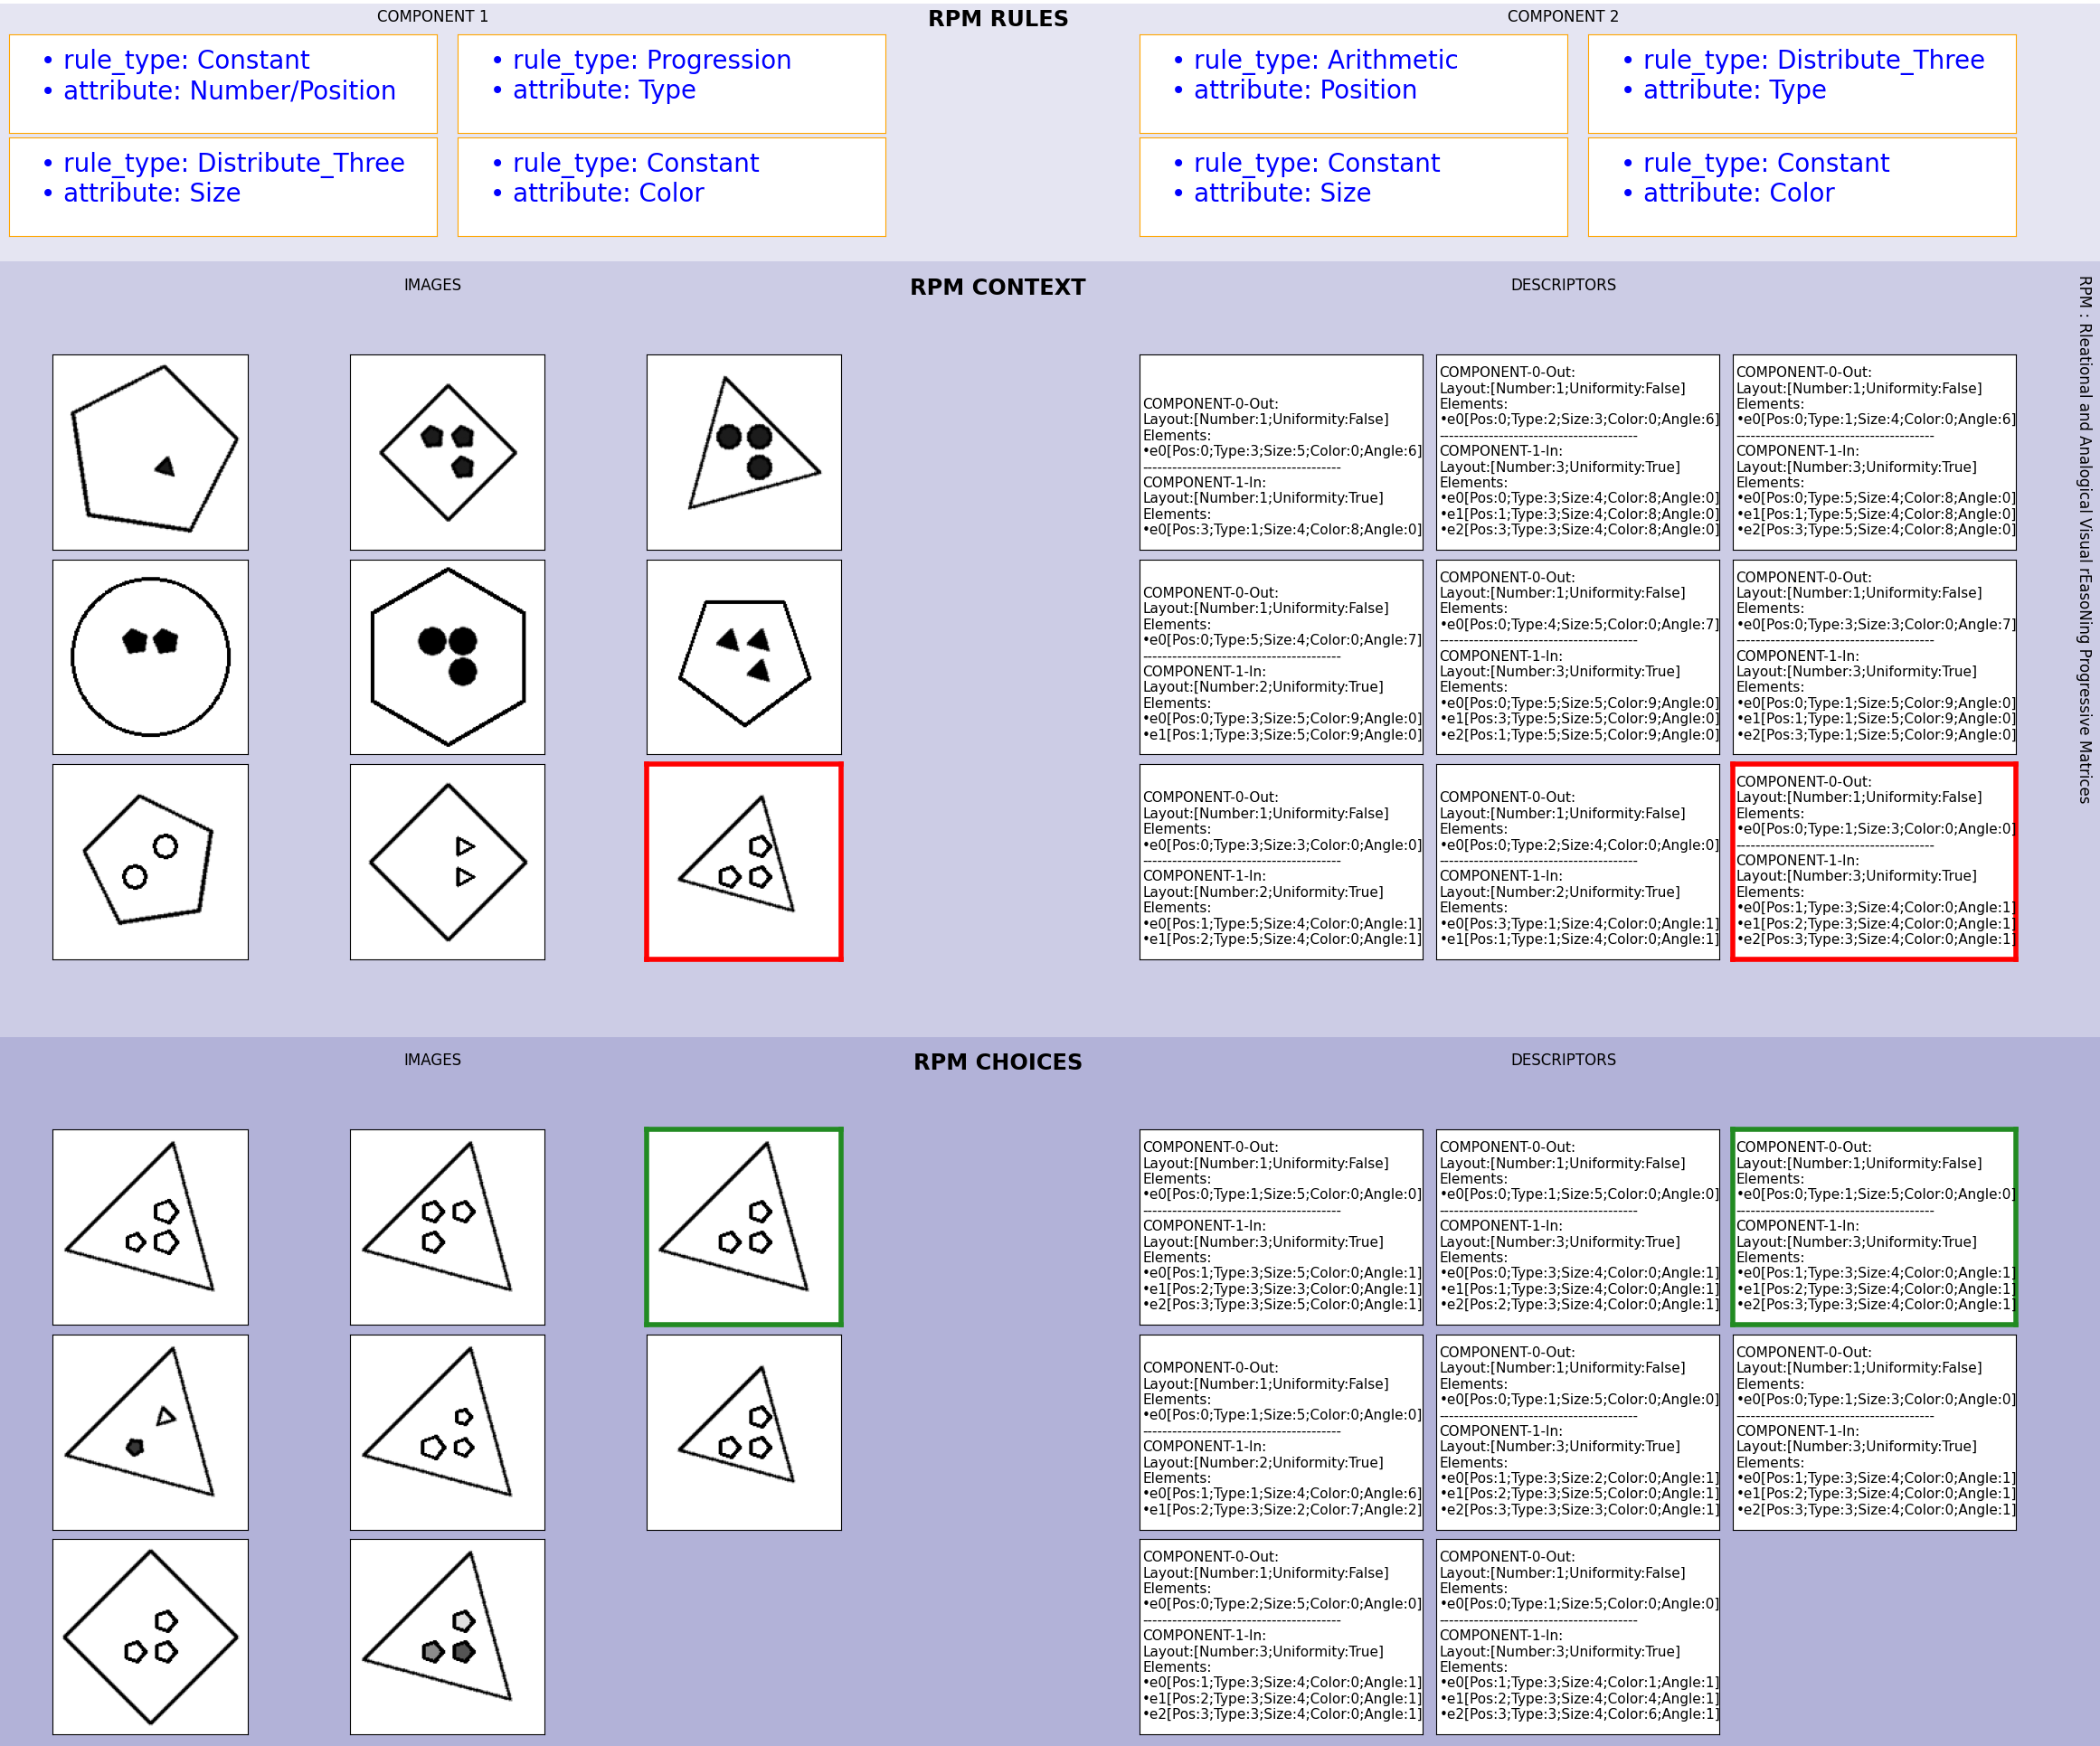

In [ ]:
data_center_single = rpm_problem_data('center_single',0)
data_distribute_four = rpm_problem_data('distribute_four',0)
data_distribute_nine = rpm_problem_data('distribute_nine',0)
data_in_out_single = rpm_problem_data('in_center_single_out_center_single',0)
data_in_out_four = rpm_problem_data('in_distribute_four_out_center_single',0)
data_left_right = rpm_problem_data('left_center_single_right_center_single',0)
data_up_down = rpm_problem_data('up_center_single_down_center_single',0)

canvas = rpm_canvas()
rpm_oracle(canvas, data_in_out_four, show_hint=False)

#### **Do you want to play !!!**

<div align="center">
  <img src="../../assets/images/neo_wants_to_play_matrix_movie.png" alt="Alt text">
</div>


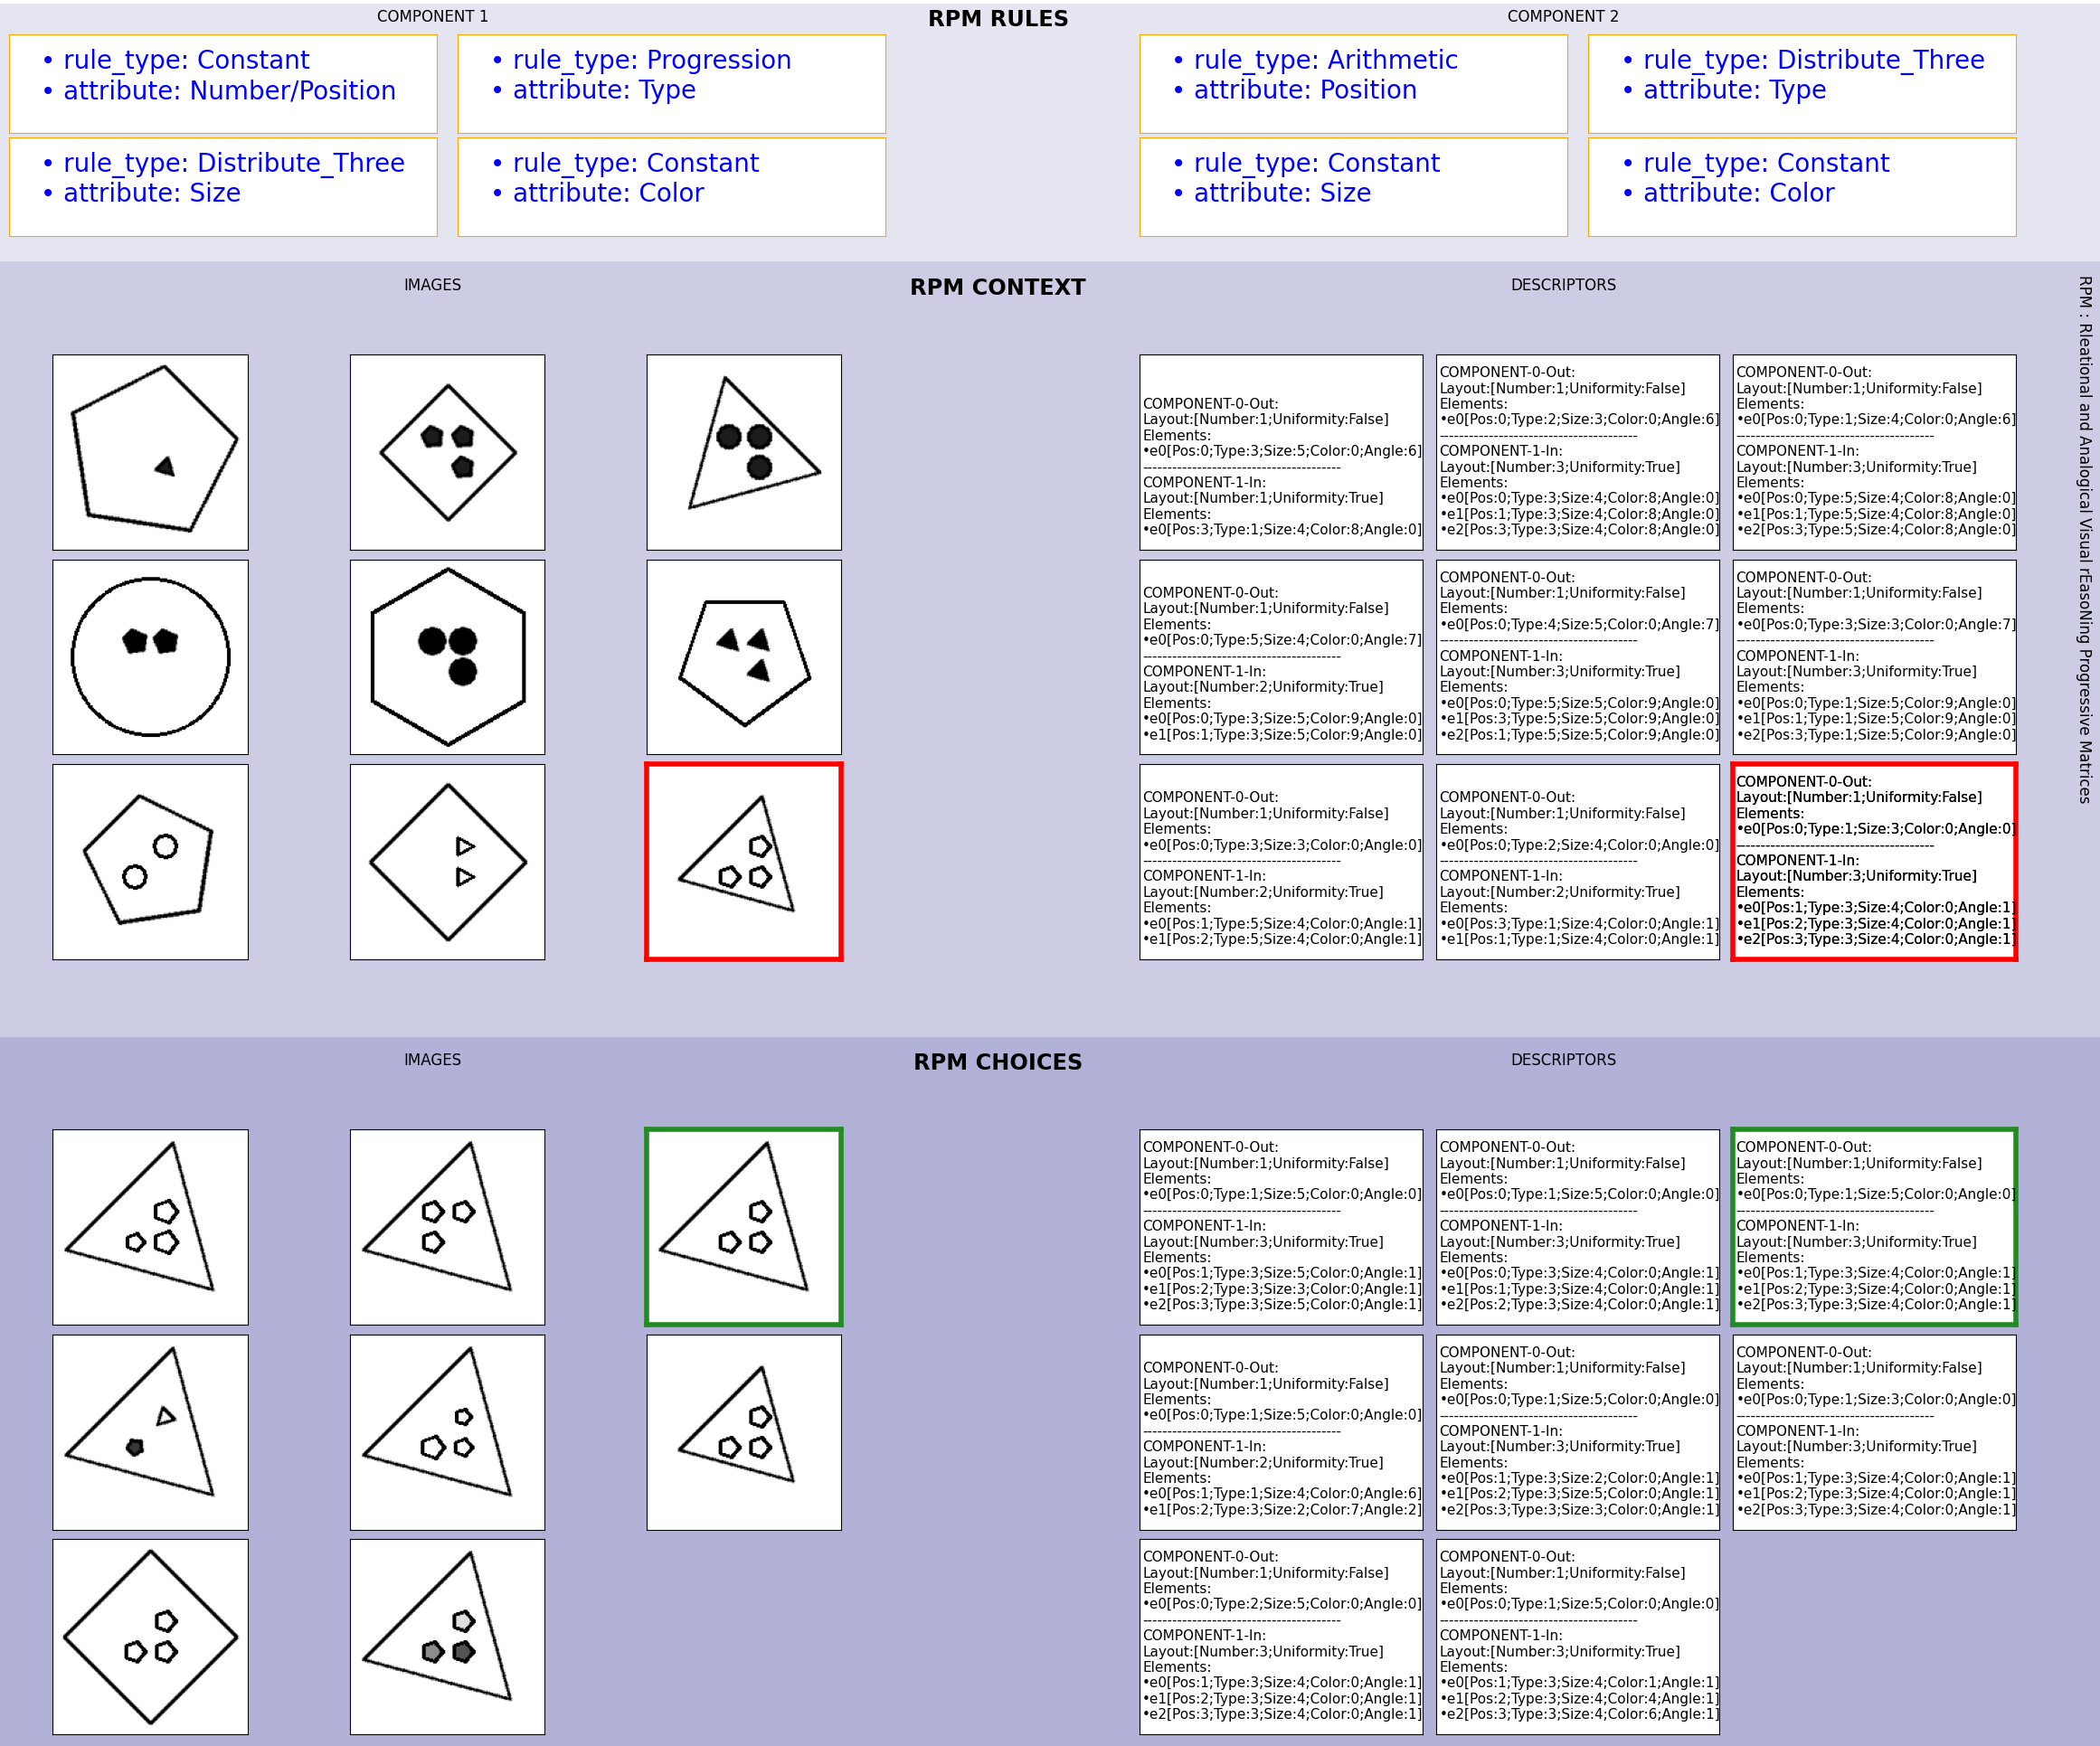

In [ ]:
# Reading you attempt
answer = int(input("Enter the id of your answer between [0,7]"))
pick_rpm_answer(canvas, data_in_out_four,choice=answer)


## 2. RPM as a Pytorch Custom Dataset